# Exhaustive AME(5,2) parallel-channel disentangler search

This notebook keeps the canonical five-qubit AME preparation unchanged and searches every valid pair of disjoint teleportation channels.

- A labelled assignment is `(A input -> A output, B input -> B output)` with four different AME qubits.
- There are 120 labelled assignments and 60 physically distinct assignments; swapping the names A and B does not change the operator.
- For every physical assignment, the two source/input qubits are untouched. The disentangler acts only on the other three AME qubits: the two outputs and one leftover qubit.
- Every candidate is verified against the complete five-qubit target state consisting of two Phi-plus pairs and a zero leftover qubit.
- Ranking is lexicographic: minimize two-qubit gates first, then single-qubit gates, then depth.

The earlier W012 reduction is generalized here. For each channel assignment, the four required conditional states define only a four-dimensional subspace of the active three-qubit register. The code enumerates all **64 Clifford completions** on the unused orthogonal subspace, applies Bravyi-Maslov synthesis to every completion, and retains the best circuit.

This is an offline Clifford calculation. It does not connect to IBM Quantum or submit QPU jobs.

**Hardware note.** Gate count is a backend-independent error proxy, not a guarantee of the highest QPU fidelity. After this synthesis search, transpile the leading circuits for the selected backend and use its current directed two-qubit, one-qubit, and readout calibration errors (for example through the existing Mapomatic layout step) to choose the physical placement.

## 1. AME state, Clifford-completion construction, and exhaustive optimizer

In [1]:
from itertools import combinations, permutations, product
from pathlib import Path

import numpy as np
import pandas as pd
from qiskit import QuantumCircuit
from qiskit.quantum_info import Clifford, Pauli, Statevector
from qiskit.synthesis import synth_clifford_bm


N_QUBITS = 5
ATOL = 1e-9


def build_ame52_preparation():
    qc = QuantumCircuit(5, name="AME(5,2)")
    qc.h(2)
    qc.h(3)
    qc.cx(2, 1)
    qc.h(2)
    qc.cx(2, 4)
    qc.cx(3, 2)
    qc.cx(1, 0)
    qc.cx(2, 0)
    return qc


AME_PREPARATION = build_ame52_preparation()
AME_STATE = Statevector.from_instruction(AME_PREPARATION)


def pure_state_fidelity(a, b):
    va = np.asarray(a.data if hasattr(a, "data") else a, dtype=complex)
    vb = np.asarray(b.data if hasattr(b, "data") else b, dtype=complex)
    return float(abs(np.vdot(va, vb)) ** 2)


def conditional_active_states(source_a, source_b):
    """Return normalized active-register states conditioned on source bits."""
    active = tuple(q for q in range(N_QUBITS) if q not in (source_a, source_b))
    full = np.asarray(AME_STATE.data, dtype=complex)
    states = {}
    for a, b in product((0, 1), repeat=2):
        vec = np.zeros(8, dtype=complex)
        for local_index in range(8):
            full_bits = [0] * N_QUBITS
            full_bits[source_a] = a
            full_bits[source_b] = b
            for local_q, physical_q in enumerate(active):
                full_bits[physical_q] = (local_index >> local_q) & 1
            full_index = sum(bit << q for q, bit in enumerate(full_bits))
            vec[local_index] = 2.0 * full[full_index]
        state = Statevector(vec)
        if not np.isclose(np.linalg.norm(vec), 1.0, atol=ATOL):
            raise RuntimeError("AME conditional state is not normalized")
        states[(a, b)] = state
    return active, states


def signed_paulis(num_qubits=3):
    result = []
    for chars in product("IXYZ", repeat=num_qubits):
        unsigned = "".join(chars)
        for sign in ("+", "-"):
            label = sign + unsigned
            pauli = Pauli(label)
            result.append((label, pauli, pauli.to_matrix()))
    return result


SIGNED_PAULIS = signed_paulis()


def pauli_action_candidates(states):
    specifications = {
        "x_a": lambda a, b: ((a ^ 1, b), 1.0),
        "x_b": lambda a, b: ((a, b ^ 1), 1.0),
        "z_a": lambda a, b: ((a, b), (-1.0) ** a),
        "z_b": lambda a, b: ((a, b), (-1.0) ** b),
        "stabilizer": lambda a, b: ((a, b), 1.0),
    }
    found = {name: [] for name in specifications}
    for label, pauli, matrix in SIGNED_PAULIS:
        for name, expected_action in specifications.items():
            ok = True
            for (a, b), source_state in states.items():
                target_key, factor = expected_action(a, b)
                observed = matrix @ source_state.data
                expected = factor * states[target_key].data
                if not np.allclose(observed, expected, atol=ATOL):
                    ok = False
                    break
            if ok:
                found[name].append((label, pauli))

    # The nonidentity +1 code stabilizer is unique for a [[3,2]] code.
    found["stabilizer"] = [
        item for item in found["stabilizer"] if item[1].to_label().lstrip("+-") != "III"
    ]
    for name, values in found.items():
        if not values:
            raise RuntimeError(f"No Pauli representative found for {name}")
    return found


def commutes(left, right):
    return bool(left.commutes(right))


def target_state(source_a, output_a, source_b, output_b):
    qc = QuantumCircuit(N_QUBITS)
    qc.h(source_a)
    qc.cx(source_a, output_a)
    qc.h(source_b)
    qc.cx(source_b, output_b)
    return Statevector.from_instruction(qc)


def full_disentangled_state(dagger_circuit, active):
    qc = QuantumCircuit(N_QUBITS)
    qc.compose(AME_PREPARATION, inplace=True)
    qc.compose(dagger_circuit, qubits=list(active), inplace=True)
    return Statevector.from_instruction(qc)


def circuit_gate_counts(circuit):
    one_q = 0
    two_q = 0
    for item in circuit.data:
        width = item.operation.num_qubits
        if width == 1:
            one_q += 1
        elif width == 2:
            two_q += 1
        else:
            raise RuntimeError(f"Unexpected {width}-qubit gate: {item.operation.name}")
    return one_q, two_q


def completion_cliffords(source_a, output_a, source_b, output_b):
    active, states = conditional_active_states(source_a, source_b)
    if output_a not in active or output_b not in active or output_a == output_b:
        raise ValueError("Outputs must be distinct nonsource qubits")
    leftover = next(q for q in active if q not in (output_a, output_b))
    local_a = active.index(output_a)
    local_b = active.index(output_b)
    local_leftover = active.index(leftover)

    representatives = pauli_action_candidates(states)
    stabilizers = representatives["stabilizer"]
    if len(stabilizers) != 1:
        raise RuntimeError(
            f"Expected one nonidentity code stabilizer, found {len(stabilizers)}"
        )
    stabilizer_label, stabilizer = stabilizers[0]

    completions = []
    seen = set()
    for x_a, z_a, x_b, z_b in product(
        representatives["x_a"],
        representatives["z_a"],
        representatives["x_b"],
        representatives["z_b"],
    ):
        # A representative multiplied by the code stabilizer acts identically
        # on the physical four-state subspace, but changes which complementary
        # Pauli can serve as X on the otherwise unused leftover qubit.  Search
        # that freedom separately for each logical-representative choice.
        x_leftover = []
        selected_logicals = (x_a[1], z_a[1], x_b[1], z_b[1])
        for label, pauli, _ in SIGNED_PAULIS:
            if pauli.anticommutes(stabilizer) and all(
                commutes(pauli, logical_pauli)
                for logical_pauli in selected_logicals
            ):
                x_leftover.append((label, pauli))

        for x_l in x_leftover:
            destabilizers = [None] * 3
            stabilizer_rows = [None] * 3
            destabilizers[local_a] = x_a[0]
            destabilizers[local_b] = x_b[0]
            destabilizers[local_leftover] = x_l[0]
            stabilizer_rows[local_a] = z_a[0]
            stabilizer_rows[local_b] = z_b[0]
            stabilizer_rows[local_leftover] = stabilizer_label
            try:
                forward = Clifford.from_dict(
                    {"destabilizer": destabilizers, "stabilizer": stabilizer_rows}
                )
            except Exception:
                continue
            key = forward.tableau.tobytes()
            if key in seen:
                continue
            seen.add(key)
            completions.append(forward)

    if len(completions) != 64:
        raise RuntimeError(
            f"Expected 64 Clifford completions, found {len(completions)} for "
            f"{source_a}->{output_a}, {source_b}->{output_b}"
        )
    return active, leftover, completions


def optimize_configuration(source_a, output_a, source_b, output_b):
    active, leftover, completions = completion_cliffords(
        source_a, output_a, source_b, output_b
    )
    desired = target_state(source_a, output_a, source_b, output_b)
    candidates = []
    for completion_index, forward in enumerate(completions):
        dagger = synth_clifford_bm(forward.adjoint())
        fidelity = pure_state_fidelity(full_disentangled_state(dagger, active), desired)
        if not np.isclose(fidelity, 1.0, atol=ATOL):
            raise RuntimeError(
                f"Completion {completion_index} failed full-state verification: {fidelity}"
            )
        one_q, two_q = circuit_gate_counts(dagger)
        candidates.append(
            {
                "circuit": dagger,
                "completion_index": completion_index,
                "one_qubit_gates": one_q,
                "two_qubit_gates": two_q,
                "depth": dagger.depth(),
                "fidelity": fidelity,
            }
        )
    candidates.sort(
        key=lambda row: (
            row["two_qubit_gates"],
            row["one_qubit_gates"],
            row["depth"],
            row["completion_index"],
        )
    )
    best = candidates[0]
    best.update(
        {
            "source_a": source_a,
            "output_a": output_a,
            "source_b": source_b,
            "output_b": output_b,
            "leftover": leftover,
            "active": active,
            "completion_count": len(completions),
        }
    )
    return best


def search_all_pairings():
    results = []
    total = 60
    for source_a, source_b in combinations(range(N_QUBITS), 2):
        remaining = [q for q in range(N_QUBITS) if q not in (source_a, source_b)]
        for output_a, output_b in permutations(remaining, 2):
            best = optimize_configuration(source_a, output_a, source_b, output_b)
            results.append(best)
            if len(results) % 10 == 0 or len(results) == total:
                print(f"Optimized {len(results)}/{total} distinct pairings.")
    results.sort(
        key=lambda row: (
            row["two_qubit_gates"],
            row["one_qubit_gates"],
            row["depth"],
            row["source_a"],
            row["output_a"],
            row["source_b"],
            row["output_b"],
        )
    )
    return results


## 2. Run the exhaustive search

In [2]:
best_results = search_all_pairings()

assert len(best_results) == 60
assert all(row["completion_count"] == 64 for row in best_results)
assert all(np.isclose(row["fidelity"], 1.0, atol=ATOL) for row in best_results)

print("Search complete: 60 distinct physical pairings, 64 completions per pairing.")
print("All selected circuits passed full five-qubit target-state verification.")

Optimized 10/60 distinct pairings.


Optimized 20/60 distinct pairings.


Optimized 30/60 distinct pairings.


Optimized 40/60 distinct pairings.


Optimized 50/60 distinct pairings.


Optimized 60/60 distinct pairings.
Search complete: 60 distinct physical pairings, 64 completions per pairing.
All selected circuits passed full five-qubit target-state verification.


## 3. Save the 60 physical and 120 labelled rankings

In [3]:
from IPython.display import display


def local_gate_sequence(circuit):
    pieces = []
    for item in circuit.data:
        local_qubits = [circuit.find_bit(qubit).index for qubit in item.qubits]
        arguments = ",".join(f"q{index}" for index in local_qubits)
        pieces.append(f"{item.operation.name}({arguments})")
    return " | ".join(pieces)


def serializable_result(row, physical_rank):
    return {
        "physical_rank": physical_rank,
        "channel_A": f"q{row['source_a']}->q{row['output_a']}",
        "channel_B": f"q{row['source_b']}->q{row['output_b']}",
        "source_A": row["source_a"],
        "output_A": row["output_a"],
        "source_B": row["source_b"],
        "output_B": row["output_b"],
        "leftover": row["leftover"],
        "active_AME_qubits": ",".join(str(q) for q in row["active"]),
        "local_wire_map": ", ".join(
            f"local q{local}=AME q{physical}"
            for local, physical in enumerate(row["active"])
        ),
        "two_qubit_gates": row["two_qubit_gates"],
        "single_qubit_gates": row["one_qubit_gates"],
        "depth": row["depth"],
        "completion_index": row["completion_index"],
        "completions_tested": row["completion_count"],
        "full_state_fidelity": row["fidelity"],
        "local_gate_sequence": local_gate_sequence(row["circuit"]),
    }


physical_rows = [
    serializable_result(row, physical_rank=rank)
    for rank, row in enumerate(best_results, start=1)
]
physical_ranking = pd.DataFrame(physical_rows)

# Restore both A/B label choices. Each pair of rows below uses the same physical
# circuit; the second row only exchanges the channel names.
labelled_rows = []
for row in physical_rows:
    labelled_rows.append({**row, "label_variant": "canonical"})
    swapped = dict(row)
    swapped.update(
        {
            "channel_A": row["channel_B"],
            "channel_B": row["channel_A"],
            "source_A": row["source_B"],
            "output_A": row["output_B"],
            "source_B": row["source_A"],
            "output_B": row["output_A"],
            "label_variant": "A/B swapped",
        }
    )
    labelled_rows.append(swapped)
labelled_ranking = pd.DataFrame(labelled_rows)

assert len(physical_ranking) == 60
assert len(labelled_ranking) == 120

OUTPUT_DIR = Path.cwd() / "pair_search_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

physical_csv = OUTPUT_DIR / "pair_rank60.csv"
labelled_csv = OUTPUT_DIR / "pair_rank120.csv"
physical_ranking.to_csv(physical_csv, index=False)
labelled_ranking.to_csv(labelled_csv, index=False)

print("Saved:", physical_csv.resolve())
print("Saved:", labelled_csv.resolve())
display(physical_ranking.head(10))

Saved: /home/claude/pair_search_outputs/pair_rank60.csv
Saved: /home/claude/pair_search_outputs/pair_rank120.csv


,physical_rank,channel_A,channel_B,source_A,output_A,source_B,output_B,leftover,active_AME_qubits,local_wire_map,two_qubit_gates,single_qubit_gates,depth,completion_index,completions_tested,full_state_fidelity,local_gate_sequence
0,1,q2->q0,q3->q1,2,0,3,1,4,"0,1,4","local q0=AME q0, local q1=AME q1, local q2=AME q4",3,5,6,0,64,1.0,"h(q0) | s(q0) | h(q1) | cx(q0,q1) | sdg(q0) | ..."
1,2,q0->q2,q4->q1,0,2,4,1,3,"1,2,3","local q0=AME q1, local q1=AME q2, local q2=AME q3",3,6,7,8,64,1.0,"cx(q1,q2) | h(q2) | s(q2) | cx(q0,q1) | h(q0) ..."
2,3,q0->q2,q4->q3,0,2,4,3,1,"1,2,3","local q0=AME q1, local q1=AME q2, local q2=AME q3",3,6,7,7,64,1.0,"cx(q1,q2) | sdg(q2) | h(q2) | cx(q0,q2) | h(q2..."
3,4,q2->q1,q4->q0,2,1,4,0,3,"0,1,3","local q0=AME q0, local q1=AME q1, local q2=AME q3",3,6,7,8,64,1.0,"h(q2) | s(q2) | cx(q0,q1) | h(q0) | s(q0) | cx..."
4,5,q0->q2,q3->q4,0,2,3,4,1,"1,2,4","local q0=AME q1, local q1=AME q2, local q2=AME q4",3,6,9,7,64,1.0,"sdg(q2) | h(q2) | cx(q0,q2) | h(q2) | s(q2) | ..."
5,6,q2->q1,q3->q0,2,1,3,0,4,"0,1,4","local q0=AME q0, local q1=AME q1, local q2=AME q4",3,7,6,42,64,1.0,"h(q0) | h(q1) | s(q1) | z(q2) | s(q2) | cx(q0,..."
6,7,q2->q0,q4->q1,2,0,4,1,3,"0,1,3","local q0=AME q0, local q1=AME q1, local q2=AME q3",3,7,7,0,64,1.0,sdg(q0) | h(q0) | z(q1) | sdg(q1) | h(q1) | cx...
7,8,q2->q1,q4->q3,2,1,4,3,0,"0,1,3","local q0=AME q0, local q1=AME q1, local q2=AME q3",3,7,7,38,64,1.0,"s(q1) | cx(q0,q2) | h(q2) | s(q2) | cx(q1,q2) ..."
8,9,q1->q2,q4->q0,1,2,4,0,3,"0,2,3","local q0=AME q0, local q1=AME q2, local q2=AME q3",3,8,7,10,64,1.0,"s(q0) | s(q1) | h(q2) | s(q2) | cx(q1,q2) | sd..."
9,10,q2->q1,q3->q4,2,1,3,4,0,"0,1,4","local q0=AME q0, local q1=AME q1, local q2=AME q4",3,8,8,34,64,1.0,"s(q1) | s(q2) | cx(q1,q2) | h(q2) | s(q2) | cx..."


## 4. Compare the former W012/V234 choices with the new best pairings

In [4]:
def find_physical_result(pair_1, pair_2):
    requested = {tuple(pair_1), tuple(pair_2)}
    for row in best_results:
        observed = {
            (row["source_a"], row["output_a"]),
            (row["source_b"], row["output_b"]),
        }
        if observed == requested:
            return row
    raise KeyError(f"Pairing not found: {requested}")


comparison_items = [
    ("Best 1", best_results[0]),
    ("Best 2", best_results[1]),
    ("Former W012 choice", find_physical_result((4, 2), (3, 0))),
    ("Former V234 choice", find_physical_result((0, 4), (1, 3))),
]

comparison_rows = []
for label, row in comparison_items:
    serialized = serializable_result(
        row,
        physical_rank=best_results.index(row) + 1,
    )
    comparison_rows.append({"selection": label, **serialized})

known_vs_best = pd.DataFrame(comparison_rows)
known_csv = OUTPUT_DIR / "known_vs_best.csv"
known_vs_best.to_csv(known_csv, index=False)

display(
    known_vs_best[
        [
            "selection",
            "physical_rank",
            "channel_A",
            "channel_B",
            "leftover",
            "active_AME_qubits",
            "two_qubit_gates",
            "single_qubit_gates",
            "depth",
            "full_state_fidelity",
        ]
    ]
)
print("Saved:", known_csv.resolve())

,selection,physical_rank,channel_A,channel_B,leftover,active_AME_qubits,two_qubit_gates,single_qubit_gates,depth,full_state_fidelity
0,Best 1,1,q2->q0,q3->q1,4,"0,1,4",3,5,6,1.0
1,Best 2,2,q0->q2,q4->q1,3,"1,2,3",3,6,7,1.0
2,Former W012 choice,38,q3->q0,q4->q2,1,"0,1,2",3,11,10,1.0
3,Former V234 choice,58,q0->q4,q1->q3,2,"2,3,4",3,13,10,1.0


Saved: /home/claude/pair_search_outputs/known_vs_best.csv


## 5. Plot and save the two best distinct Qiskit circuits

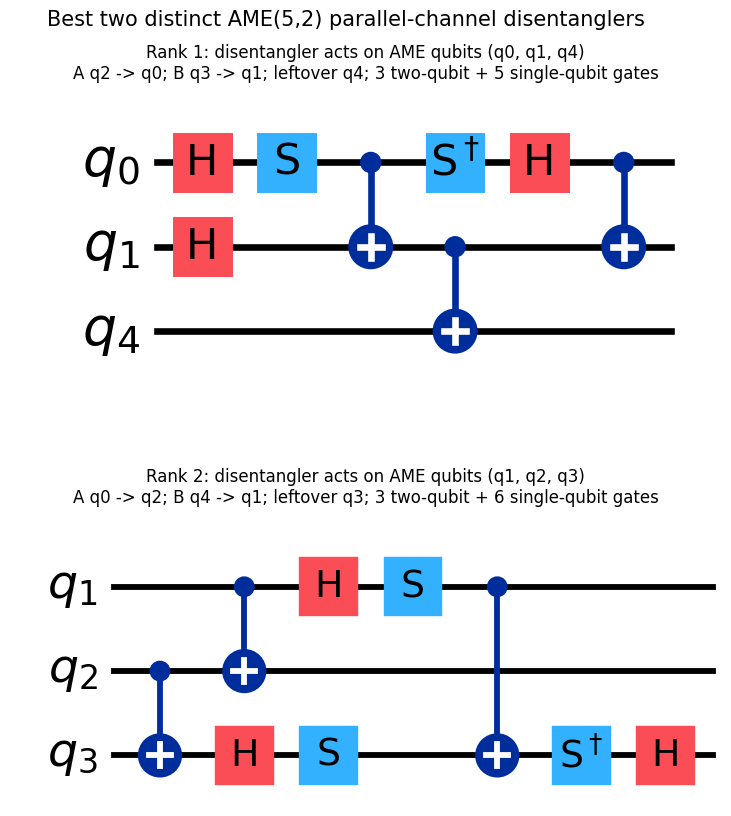

Saved: /home/claude/pair_search_outputs/best1.png
Saved: /home/claude/pair_search_outputs/best2.png
Saved: /home/claude/pair_search_outputs/best_compare.png


In [5]:
import matplotlib.pyplot as plt


def physical_ame_circuit(row):
    """Embed the selected three-wire operator on its actual AME qubits."""
    circuit = QuantumCircuit(5)
    circuit.compose(
        row["circuit"],
        qubits=list(row["active"]),
        inplace=True,
    )
    return circuit


def result_title(rank, row):
    acted_on = ", ".join(f"q{qubit}" for qubit in row["active"])
    return (
        f"Rank {rank}: disentangler acts on AME qubits ({acted_on})\n"
        f"A q{row['source_a']} -> q{row['output_a']}; "
        f"B q{row['source_b']} -> q{row['output_b']}; "
        f"leftover q{row['leftover']}; "
        f"{row['two_qubit_gates']} two-qubit + "
        f"{row['one_qubit_gates']} single-qubit gates"
    )


def draw_qiskit_circuit(circuit, axis, title):
    # The circuit has five AME wires. Qiskit hides the untouched source wires,
    # leaving the actual physical labels of the three acted-on AME qubits.
    circuit.draw(
        output="mpl",
        style="iqp",
        fold=-1,
        idle_wires=False,
        ax=axis,
    )
    axis.set_title(title, fontsize=12, pad=12)


best_two = best_results[:2]
plot_paths = []
for rank, row in enumerate(best_two, start=1):
    path = OUTPUT_DIR / f"best{rank}.png"
    figure, axis = plt.subplots(figsize=(15, 4.2))
    draw_qiskit_circuit(
        physical_ame_circuit(row),
        axis,
        result_title(rank, row),
    )
    figure.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.20)
    plt.close(figure)
    plot_paths.append(path)

comparison_path = OUTPUT_DIR / "best_compare.png"
comparison_figure, axes = plt.subplots(2, 1, figsize=(16, 9))
for rank, (axis, row) in enumerate(zip(axes, best_two), start=1):
    draw_qiskit_circuit(
        physical_ame_circuit(row),
        axis,
        result_title(rank, row),
    )
comparison_figure.suptitle(
    "Best two distinct AME(5,2) parallel-channel disentanglers",
    fontsize=15,
    y=0.995,
)
comparison_figure.subplots_adjust(hspace=0.48, top=0.90)
comparison_figure.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight",
    pad_inches=0.25,
)
plt.show()

for path in plot_paths:
    print("Saved:", path.resolve())
print("Saved:", comparison_path.resolve())


## 6. Apply either selected circuit to a five-qubit experiment

In [6]:
def apply_selected_disentangler(qc, selected_result, ame_qubits):
    """Compose a selected local three-qubit circuit on its AME qubits."""
    physical_targets = [ame_qubits[index] for index in selected_result["active"]]
    qc.compose(
        selected_result["circuit"],
        qubits=physical_targets,
        inplace=True,
    )


BEST_1 = best_results[0]
BEST_2 = best_results[1]

print(
    "BEST_1:",
    f"A q{BEST_1['source_a']}->q{BEST_1['output_a']},",
    f"B q{BEST_1['source_b']}->q{BEST_1['output_b']},",
    f"active={BEST_1['active']}",
)
print(
    "BEST_2:",
    f"A q{BEST_2['source_a']}->q{BEST_2['output_a']},",
    f"B q{BEST_2['source_b']}->q{BEST_2['output_b']},",
    f"active={BEST_2['active']}",
)

BEST_1: A q2->q0, B q3->q1, active=(0, 1, 4)
BEST_2: A q0->q2, B q4->q1, active=(1, 2, 3)


## 7. Verify the Former V234 choice is physical_rank 58, and plot its circuit

The MCM cascade notebook now uses this exact pairing (source q0->q4, source
q1->q3, leftover q2) as its rank-58 decoder. Confirm its rank against the
full 60-pairing search and render its circuit the same way as the best-two
plots above.


physical_rank: 58 / 60
channel_A: q0->q4, channel_B: q1->q3, leftover q2
active AME qubits: (2, 3, 4)
two_qubit_gates=3, single_qubit_gates=13, depth=10, fidelity=1.0000000000


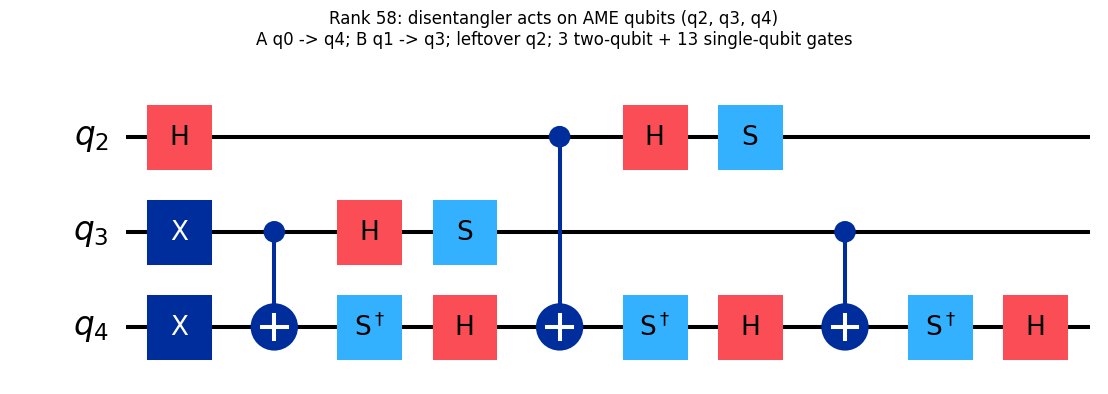

Saved: /home/claude/pair_search_outputs/former_v234_choice_rank58.png


In [7]:
FORMER_V234_CHOICE = find_physical_result((0, 4), (1, 3))
former_v234_rank = best_results.index(FORMER_V234_CHOICE) + 1

assert former_v234_rank == 58, (
    f"Expected the Former V234 choice at physical_rank 58, found {former_v234_rank}"
)

print(f"physical_rank: {former_v234_rank} / {len(best_results)}")
print(
    f"channel_A: q{FORMER_V234_CHOICE['source_a']}->q{FORMER_V234_CHOICE['output_a']}, "
    f"channel_B: q{FORMER_V234_CHOICE['source_b']}->q{FORMER_V234_CHOICE['output_b']}, "
    f"leftover q{FORMER_V234_CHOICE['leftover']}"
)
print(f"active AME qubits: {FORMER_V234_CHOICE['active']}")
print(
    f"two_qubit_gates={FORMER_V234_CHOICE['two_qubit_gates']}, "
    f"single_qubit_gates={FORMER_V234_CHOICE['one_qubit_gates']}, "
    f"depth={FORMER_V234_CHOICE['depth']}, "
    f"fidelity={FORMER_V234_CHOICE['fidelity']:.10f}"
)

former_v234_path = OUTPUT_DIR / "former_v234_choice_rank58.png"
figure, axis = plt.subplots(figsize=(15, 4.2))
draw_qiskit_circuit(
    physical_ame_circuit(FORMER_V234_CHOICE),
    axis,
    result_title(former_v234_rank, FORMER_V234_CHOICE),
)
figure.savefig(former_v234_path, dpi=200, bbox_inches="tight", pad_inches=0.20)
plt.show()

print("Saved:", former_v234_path.resolve())
